# Loss Given Default (LGD) modelling
## Parametric approach (Beta distribution) vs non-parametric approaches (kernel smoothing, expert-judgement scorecard)

**Data**: Lending Club – "All Lending Club loan data" (Kaggle, file `accepted_2007_to_2018Q4.csv`, CC0 licence):
unsecured consumer loans that were charged off, originated between 2007 and 2015.

**Outline**
1. Target variable (recovery rate / LGD) and samples
2. Exploratory analysis: shape of the distribution, point masses at the bounds, vintage effects
3. **Parametric approach** – Beta distribution fitted by method of moments and maximum likelihood; zero-one-inflated Beta
4. **Non-parametric approach (kernel smoothing)** – estimation of the recovery-rate *density* on [0,1]:
   naive Gaussian kernel, reflection, logit transform, and the Beta kernel of Chen (1999) used by Renault & Scaillet (2004)
5. Comparison of the density estimators (out-of-sample likelihood, Kolmogorov-Smirnov, LGD quantiles)
6. **Expert-judgement scorecard** – segmentation into homogeneous LGD pools, calibration to the long-run average
7. Conditional parametric benchmark (two-stage model: logit + Beta regression) and validation
8. Recovery-rate densities by LGD pool (scorecard × Beta kernel), stress quantiles and a *downturn* illustration
9. Limitations and next steps

> Fully reproducible: `python src/extract_lgd_data.py accepted_2007_to_2018Q4.csv data/lgd_lendingclub_2007_2015.csv.gz`
> then run this notebook.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, integrate
from scipy.special import logit
import statsmodels.api as sm
from statsmodels.othermod.betareg import BetaModel
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
pd.set_option("display.width", 140)

# Fixed-order categorical palette and a sober chart style
C1, C2, C3, GREY = "#2a78d6", "#eb6834", "#1baf7a", "#8a8984"
plt.rcParams.update({
    "figure.figsize": (9, 4.5), "figure.dpi": 110, "axes.spines.top": False,
    "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e1",
    "grid.linewidth": 0.6, "axes.edgecolor": "#8a8984", "axes.labelcolor": "#33322f",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
    "font.size": 10, "lines.linewidth": 2,
})
RNG = np.random.default_rng(42)
DATA_PATH = "../data/lgd_lendingclub_2007_2015.csv.gz"

## 1. Target variable and samples

Definitions (simplified, undiscounted *workout* LGD – see section 9):

$$EAD = \text{funded amount} - \text{principal repaid}, \qquad RR = \frac{\text{recoveries} - \text{collection fees}}{EAD}, \qquad LGD = 1 - RR \in [0;1]$$

**Data-driven scope**: the share of defaults with no recovery at all rises sharply for recent default years (2016 onwards).
This reflects **recovery processes still open** at the extraction date (end of 2018), not genuine total losses. In line with the
principle of the EBA guidelines on incomplete recovery processes, only defaults observed between **2008 and 2015** (at least three
years of workout history) are kept.

In [2]:
raw = pd.read_csv(DATA_PATH)
raw["default_year"] = raw["default_year"].astype("Int64")
completeness = (raw.groupby("default_year")
                   .agg(n_defaults=("lgd", "size"), mean_lgd=("lgd", "mean"),
                        share_zero_RR=("rr", lambda s: (s == 0).mean())))
display(completeness.loc[2008:2019])

df = raw[raw["default_year"].between(2008, 2015)].copy()
df["log_inc"] = np.log1p(df["annual_inc"])
df["log_ead"] = np.log(df["ead"])
df["owner"] = df["home_ownership"].isin(["OWN", "MORTGAGE"]).astype(int)
df["small_bus"] = (df["purpose"] == "small_business").astype(int)
df["term60"] = (df["term_months"] == 60).astype(int)
df = df.dropna(subset=["annual_inc", "dti", "revol_util", "int_rate"])

train, test = train_test_split(df, test_size=0.30, random_state=42, stratify=df["default_year"])
print(f"Modelling sample: {len(df):,} defaults  |  development: {len(train):,}  |  test: {len(test):,}")
print(f"Default-weighted mean LGD: development {train.lgd.mean():.3f} – test {test.lgd.mean():.3f}")

,n_defaults,mean_lgd,share_zero_RR
default_year,,,
2008,185,0.9385,0.0270
2009,389,0.9362,0.0231
2010,680,0.9307,0.0044
2011,1189,0.9169,0.0008
2012,2638,0.9367,0.0008
2013,6462,0.9120,0.0245
2014,14955,0.8894,0.1213
2015,31615,0.8854,0.1978
2016,49123,0.9023,0.2173


Modelling sample: 58,057 defaults  |  development: 40,639  |  test: 17,418
Default-weighted mean LGD: development 0.893 – test 0.893


## 2. Exploratory analysis

Key point for the choice of method: the recovery-rate distribution is **mixed** – a point mass at 0 (no recovery),
an almost negligible mass at 1, and a continuous part on (0,1). Any approach, parametric or not, must treat these point
masses separately; otherwise the estimated density is biased.

,value
P(RR = 0),0.1423
P(RR = 1),0.0007
Mean RR (continuous part),0.1235
Median RR (continuous part),0.1294
Std. dev. (continuous part),0.1065
Skewness,2.8992
Excess kurtosis,14.7807


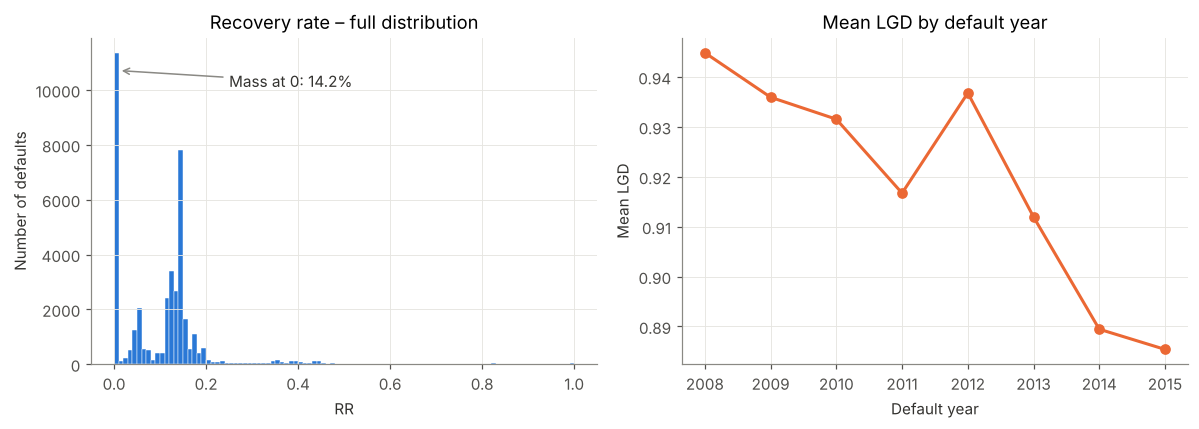

In [3]:
rr_tr, rr_te = train["rr"].to_numpy(), test["rr"].to_numpy()
p0, p1 = (rr_tr == 0).mean(), (rr_tr == 1).mean()
y_tr = rr_tr[(rr_tr > 0) & (rr_tr < 1)]          # continuous part (development)
y_te = rr_te[(rr_te > 0) & (rr_te < 1)]          # continuous part (test)

summary = pd.Series({
    "P(RR = 0)": p0, "P(RR = 1)": p1, "Mean RR (continuous part)": y_tr.mean(),
    "Median RR (continuous part)": np.median(y_tr), "Std. dev. (continuous part)": y_tr.std(),
    "Skewness": stats.skew(y_tr), "Excess kurtosis": stats.kurtosis(y_tr),
})
display(summary.to_frame("value"))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(rr_tr, bins=100, range=(0, 1), color=C1, edgecolor="white", linewidth=0.3)
ax[0].set(title="Recovery rate – full distribution", xlabel="RR", ylabel="Number of defaults")
ax[0].annotate(f"Mass at 0: {p0:.1%}", xy=(0.01, ax[0].get_ylim()[1] * 0.9), xytext=(0.25, ax[0].get_ylim()[1] * 0.85),
               arrowprops=dict(arrowstyle="->", color=GREY), color="#33322f")
yr = df.groupby("default_year").agg(lgd=("lgd", "mean"), n=("lgd", "size"))
ax[1].plot(yr.index, yr["lgd"], marker="o", color=C2)
ax[1].set(title="Mean LGD by default year", xlabel="Default year", ylabel="Mean LGD")
plt.tight_layout(); plt.show()

**Reading**: the continuous part is heavily concentrated around RR ≈ 10–15% (LGD ≈ 85–90%), with strong positive skewness.
This peaked shape is consistent with Lending Club's practice of selling charged-off receivables to debt buyers at a price close
to a fixed percentage of face value: recoveries reflect the sale price more than individual borrower behaviour. We therefore
expect (i) a poor fit of the Beta distribution to these peaks and (ii) limited discriminatory power of borrower risk factors –
two hypotheses tested below.

## 3. Parametric approach – fitting a Beta distribution

The Beta distribution $\mathcal{B}(\alpha,\beta)$ is the traditional benchmark for recovery rates (e.g. CreditMetrics,
LossCalc-type models) because it lives on [0,1] and covers a wide range of shapes with only two parameters.

- **Method of moments**: $\alpha = m\,c$, $\beta = (1-m)\,c$ with $c = \frac{m(1-m)}{v} - 1$
- **Maximum likelihood** (support fixed to [0,1])
- **Zero-one-inflated Beta (ZOIB)**: $F(x) = p_0\,\mathbb{1}_{x\ge0} + (1-p_0-p_1)\,F_{\mathcal B}(x) + p_1\,\mathbb{1}_{x\ge1}$,
  which handles the point masses explicitly.

In [4]:
def beta_mom(y):
    m, v = y.mean(), y.var(ddof=1)
    c = m * (1 - m) / v - 1
    return m * c, (1 - m) * c

a_mom, b_mom = beta_mom(y_tr)
a_mle, b_mle, _, _ = stats.beta.fit(y_tr, floc=0, fscale=1)
params = pd.DataFrame({"alpha": [a_mom, a_mle], "beta": [b_mom, b_mle]}, index=["Method of moments", "Maximum likelihood"])
params["implied mean"] = params.alpha / (params.alpha + params.beta)
params["implied mode"] = np.where(params.alpha > 1, (params.alpha - 1) / (params.alpha + params.beta - 2), 0.0)  # alpha<1: density unbounded at 0
display(params)

def zoib_mean_lgd(a, b, p0, p1):
    """Mean LGD implied by the zero-one-inflated Beta distribution."""
    return 1 - ((1 - p0 - p1) * a / (a + b) + p1)

print(f"Mean LGD implied by ZOIB (MLE): {zoib_mean_lgd(a_mle, b_mle, p0, p1):.4f}  |  observed (development): {train.lgd.mean():.4f}")

,alpha,beta,implied mean,implied mode
Method of moments,1.0535,7.4800,0.1235,0.0082
Maximum likelihood,0.6053,4.3772,0.1215,0.0000


Mean LGD implied by ZOIB (MLE): 0.8952  |  observed (development): 0.8935


## 4. Non-parametric approach – kernel estimation of the recovery-rate density

We estimate the density $f$ of the continuous part of RR without any shape assumption. The core difficulty is **boundary
bias**: a standard Gaussian kernel puts probability mass outside [0,1] and underestimates the density near the bounds – exactly
where recoveries concentrate. Four estimators are compared:

| Estimator | Principle | Boundary bias |
|---|---|---|
| Naive Gaussian | $\hat f(x)=\frac1{nh}\sum K\!\left(\frac{x-X_i}{h}\right)$ | yes (mass leakage) |
| Reflection | adds mirror images $-X_i$ and $2-X_i$ | corrected at order 0 |
| Logit transform | Gaussian KDE on $Z=\text{logit}(X)$, then change of variable | none (support respected) |
| **Beta kernel (Chen, 1999)** | $\hat f(x)=\frac1n\sum_i \text{Beta}\!\left(X_i;\ \tfrac{x}{b}+1,\ \tfrac{1-x}{b}+1\right)$ | none – kernel supported on [0,1] whose shape adapts to $x$ |

The Beta kernel is the approach proposed by **Renault & Scaillet (2004)** for recovery-rate densities: it is free of boundary
bias and its variance shrinks near the bounds.

**Bandwidth selection**: to compare the four estimators on an equal footing, each uses **the same likelihood cross-validation
procedure**: estimation on a development subsample (8,000 points), choice of the bandwidth maximising the log-likelihood of a
second, disjoint subsample (4,000 points). The test sample is kept untouched for the final comparison. Note: for the Beta kernel,
the *effective* bandwidth at $x$ is the kernel's standard deviation, $\approx\sqrt{b\,x(1-x)}$; a very small $b$ therefore does
not mean no smoothing.

,selected bandwidth,effective kernel std. dev. at x = 13%,optimum on grid edge?
Naive Gaussian kernel,7.67e-04,0.0008,False
Gaussian kernel + reflection,7.67e-04,0.0008,False
Gaussian kernel on logit,2.13e-02,0.0024,False
Beta kernel (Chen),8.77e-06,0.0010,False


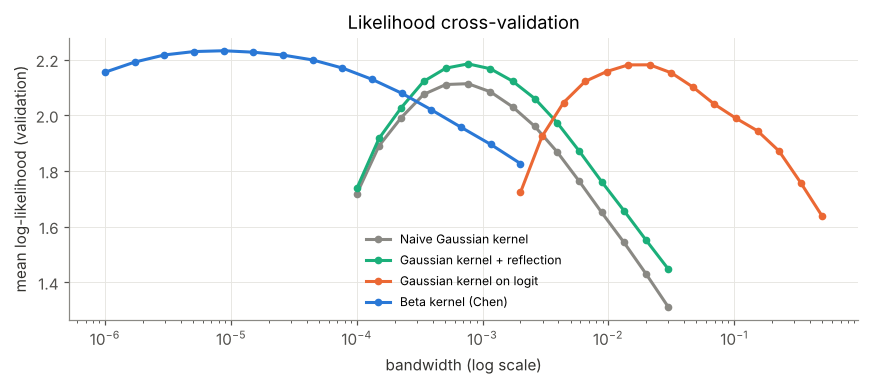

In [5]:
# Non-uniform grid, denser near the bounds, for accurate numerical integration
GRID = np.unique(np.r_[np.geomspace(1e-6, 0.02, 400), np.linspace(0.02, 0.98, 1200), 1 - np.geomspace(1e-6, 0.02, 400)])

def kde_gauss(x, data, h, chunk=400):
    out = np.empty(len(x))
    for i in range(0, len(x), chunk):
        out[i:i + chunk] = stats.norm.pdf((x[i:i + chunk, None] - data[None, :]) / h).mean(axis=1) / h
    return out

def kde_reflect(x, data, h):
    return kde_gauss(x, data, h) + kde_gauss(x, -data, h) + kde_gauss(x, 2 - data, h)

def kde_logit(x, data, h):
    return kde_gauss(logit(x), logit(data), h) / (x * (1 - x))

def kde_beta(x, data, b, chunk=200):
    out = np.empty(len(x))
    for i in range(0, len(x), chunk):
        xx = x[i:i + chunk, None]
        out[i:i + chunk] = stats.beta.pdf(data[None, :], xx / b + 1, (1 - xx) / b + 1).mean(axis=1)
    return out

KERNELS = {
    "Naive Gaussian kernel":        (kde_gauss,   np.geomspace(1e-4, 0.03, 15)),
    "Gaussian kernel + reflection": (kde_reflect, np.geomspace(1e-4, 0.03, 15)),
    "Gaussian kernel on logit":     (kde_logit,   np.geomspace(2e-3, 0.5, 15)),
    "Beta kernel (Chen)":           (kde_beta,    np.geomspace(1e-6, 2e-3, 15)),
}
perm = RNG.permutation(y_tr)
fit_s, val_s = perm[:8000], perm[8000:12000]
bw, lcv_curves = {}, {}
for name, (fn, hs) in KERNELS.items():
    ll = np.array([np.log(np.maximum(fn(val_s, fit_s, h), 1e-12)).mean() for h in hs])
    bw[name], lcv_curves[name] = hs[ll.argmax()], (hs, ll)
bw_tab = pd.DataFrame({"selected bandwidth": bw})
bw_tab["effective kernel std. dev. at x = 13%"] = [
    h if "logit" not in k and "Beta" not in k else
    (np.sqrt(h * 0.13 * 0.87) if "Beta" in k else h * 0.13 * 0.87) for k, h in bw.items()]
bw_tab["optimum on grid edge?"] = [h in (KERNELS[k][1][0], KERNELS[k][1][-1]) for k, h in bw.items()]
display(bw_tab.style.format({"selected bandwidth": "{:.2e}", "effective kernel std. dev. at x = 13%": "{:.4f}"}))

fig, ax = plt.subplots(figsize=(8, 3.6))
for (name, (hs, ll)), c in zip(lcv_curves.items(), [GREY, C3, C2, C1]):
    ax.semilogx(hs, ll, marker="o", ms=4, color=c, label=name)
ax.set(title="Likelihood cross-validation", xlabel="bandwidth (log scale)", ylabel="mean log-likelihood (validation)")
ax.legend(loc="lower center", fontsize=8)
plt.tight_layout(); plt.show()

,"probability mass on [0,1]"
Beta – moments,1.0000
Beta – MLE,0.9994
Naive Gaussian kernel,0.9560
Gaussian kernel + reflection,0.9999
Gaussian kernel on logit,1.0000
Beta kernel (Chen),0.9982


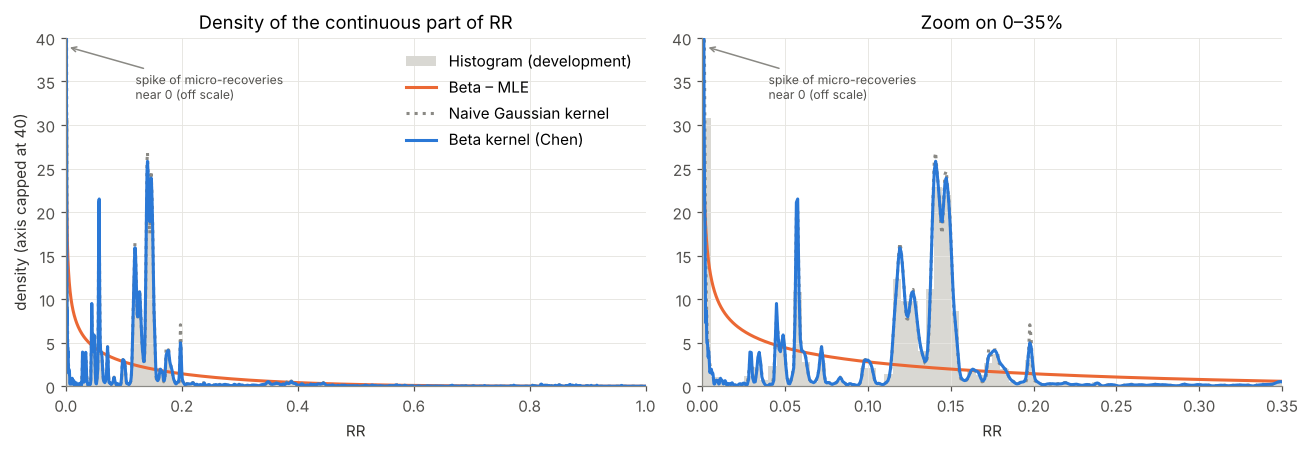

In [6]:
# Densities on the grid (same subsample as the one used for bandwidth selection)
est = fit_s
dens = {
    "Beta – moments": stats.beta.pdf(GRID, a_mom, b_mom),
    "Beta – MLE": stats.beta.pdf(GRID, a_mle, b_mle),
    **{name: fn(GRID, est, bw[name]) for name, (fn, _) in KERNELS.items()},
}
mass = {k: integrate.trapezoid(v, GRID) for k, v in dens.items()}
display(pd.Series(mass, name="probability mass on [0,1]").to_frame())

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
for a_ in ax:
    a_.hist(y_tr, bins=200, range=(0, 1), density=True, color="#d9d8d3", edgecolor="none", label="Histogram (development)")
    a_.plot(GRID, dens["Beta – MLE"], color=C2, label="Beta – MLE")
    a_.plot(GRID, dens["Naive Gaussian kernel"], color=GREY, ls=":", label="Naive Gaussian kernel")
    a_.plot(GRID, dens["Beta kernel (Chen)"], color=C1, label="Beta kernel (Chen)")
ax[0].set(title="Density of the continuous part of RR", xlabel="RR", ylabel="density (axis capped at 40)", xlim=(0, 1), ylim=(0, 40))
ax[1].set(title="Zoom on 0–35%", xlabel="RR", xlim=(0, 0.35), ylim=(0, 40))
for a_ in ax:
    a_.annotate("spike of micro-recoveries\nnear 0 (off scale)", xy=(0.002, 39), xytext=(0.04 if a_ is ax[1] else 0.12, 33),
                arrowprops=dict(arrowstyle="->", color=GREY), fontsize=8, color="#52514e")
ax[0].legend(loc="upper right")
plt.tight_layout(); plt.show()

## 5. Comparison of the density estimators (out of sample)

Criteria computed on the **test** sample (continuous part):
- **mean log-likelihood** (the higher, the better the density describes unseen data);
- **Kolmogorov-Smirnov distance** between the estimated and empirical distribution functions;
- **LGD quantiles** derived from the full mixed distribution (point masses at 0 and 1 + continuous part), relevant for stress
  testing and economic capital.

In [7]:
def cdf_from_density(f):
    F = integrate.cumulative_trapezoid(f, GRID, initial=0)
    return F / F[-1]

def mixed_rr_quantile(q, F_cont, p0=p0, p1=p1):
    """Quantile q of RR under the mixed distribution p0·δ0 + (1-p0-p1)·F_cont + p1·δ1."""
    if q <= p0:
        return 0.0
    if q >= 1 - p1:
        return 1.0
    return float(np.interp((q - p0) / (1 - p0 - p1), F_cont, GRID))

emp_sorted = np.sort(y_te)
emp_cdf_on_grid = np.searchsorted(emp_sorted, GRID, side="right") / len(emp_sorted)
rows = {}
for name, f in dens.items():
    f = f / integrate.trapezoid(f, GRID)          # renormalised on [0,1] (raw mass is reported above)
    f_te = np.interp(y_te, GRID, f)
    F = cdf_from_density(f)
    rr_q = lambda q: mixed_rr_quantile(q, F)
    rows[name] = {
        "mean log-lik. (test)": np.log(np.maximum(f_te, 1e-12)).mean(),
        "KS (test)": np.abs(F - emp_cdf_on_grid).max(),
        "LGD q25": 1 - rr_q(0.75),
        "LGD median": 1 - rr_q(0.5),
        "LGD q75": 1 - rr_q(0.25),
        "LGD q80": 1 - rr_q(0.20),
    }
emp = np.sort(rr_te)
rows["Empirical (test)"] = {"mean log-lik. (test)": np.nan, "KS (test)": 0.0,
                            "LGD q25": 1 - np.quantile(emp, 0.75), "LGD median": 1 - np.quantile(emp, 0.5),
                            "LGD q75": 1 - np.quantile(emp, 0.25), "LGD q80": 1 - np.quantile(emp, 0.20)}
density_comparison = pd.DataFrame(rows).T
display(density_comparison)

,mean log-lik. (test),KS (test),LGD q25,LGD median,LGD q75,LGD q80
Beta – moments,1.0530,0.2281,0.8405,0.9249,0.9797,0.9891
Beta – MLE,1.1929,0.2738,0.8449,0.9476,0.9934,0.9977
Naive Gaussian kernel,2.1542,0.0628,0.8538,0.8769,0.9747,0.9989
Gaussian kernel + reflection,2.1813,0.0408,0.8544,0.8792,0.9984,0.9994
Gaussian kernel on logit,2.2017,0.0160,0.8546,0.8790,0.9989,0.9997
Beta kernel (Chen),2.2369,0.0076,0.8544,0.8791,0.9988,0.9997
Empirical (test),NaN,0.0000,0.8543,0.8794,0.9989,0.9998


**Interpretation**:
- **The Beta distribution is rejected by the data**: with α < 1 (MLE), its density is unbounded at 0 and it cannot reproduce the
  **multimodal** structure of the continuous part (peaks near 0%, 5.7%, 12%, 14–15% and 20%, most likely driven by bulk debt-sale
  prices). Its out-of-sample KS distance (≈ 0.23–0.27) is about 30 times that of the Beta kernel (≈ 0.008), and its implied median
  LGD (≈ 92–95%) overstates the observed median (≈ 88%) by 5 to 7 points.
- **Boundary-corrected kernel estimators** (reflection, logit, Chen's Beta kernel) reproduce the empirical quantiles almost exactly;
  the Beta kernel achieves the best log-likelihood and the best KS distance, consistent with Renault & Scaillet (2004). The naive
  Gaussian kernel loses about 4% of probability mass outside [0,1].
- **The mean, however, is well captured by the inflated Beta** (implied LGD 0.895 vs 0.894 observed): the Beta distribution remains
  acceptable for a segment-level mean LGD, but not for quantiles (stress testing, economic capital, *downturn*).
- Beyond the ≈ 86th percentile of LGD, the distribution is driven by the mass at RR = 0 (14% of defaults with no recovery at all):
  **explicit modelling of the bounds matters more than fine-tuning the continuous density** for tail measures.

## 6. Expert-judgement scorecard

Objective: segment the portfolio into **homogeneous LGD pools** using factors selected and weighted by expert judgement, then
calibrate each pool to the observed long-run average LGD (standard practice for IRB retail portfolios).

**Factors and economic rationale (set a priori, before looking at the data)** – more points = higher expected recovery:

| Factor | Expert rationale | Buckets → points |
|---|---|---|
| Share of principal repaid before default | demonstrated capacity/willingness to pay, lower residual debt | <15%: 0 · 15–35%: 10 · 35–55%: 20 · ≥55%: 30 |
| Months on book at default | early defaults signal fraud or structural fragility | ≤9: 0 · 10–18: 6 · >18: 12 |
| Loan term | 60-month loans: larger amounts, more fragile borrowers | 60 months: 0 · 36 months: 8 |
| Home ownership | owners: attachable assets, easier to reach | renter/other: 0 · owner/mortgage: 8 |
| Loan purpose | small-business loans: failed activity, weak recovery | small business: 0 · other: 6 |
| Declared annual income | residual repayment capacity | <40k$: 0 · 40–75k$: 5 · ≥75k$: 10 |

Good practice: expert choices are then **challenged against the data** (bivariate table below); any factor whose observed
relationship contradicts the expected direction must be documented and, where necessary, revised.

In [8]:
def expert_score(d):
    s = pd.Series(0.0, index=d.index)
    s += np.select([d.pct_principal_repaid < .15, d.pct_principal_repaid < .35, d.pct_principal_repaid < .55], [0, 10, 20], 30)
    s += np.select([d.mob_at_default <= 9, d.mob_at_default <= 18], [0, 6], 12)
    s += np.where(d.term_months == 60, 0, 8)
    s += np.where(d.owner == 1, 8, 0)
    s += np.where(d.small_bus == 1, 0, 6)
    s += np.select([d.annual_inc < 40_000, d.annual_inc < 75_000], [0, 5], 10)
    return s

FACTOR_BINS = {
    "Share of principal repaid": lambda d: pd.cut(d.pct_principal_repaid, [-1, .15, .35, .55, 1.01], right=False,
                                                    labels=["<15%", "15–35%", "35–55%", "≥55%"]),
    "Months on book at default": lambda d: pd.cut(d.mob_at_default, [-1, 9, 18, 999], labels=["≤9", "10–18", ">18"]),
    "Term": lambda d: d.term_months.map({36: "36 months", 60: "60 months"}),
    "Home ownership": lambda d: np.where(d.owner == 1, "owner/mortgage", "renter/other"),
    "Purpose": lambda d: np.where(d.small_bus == 1, "small business", "other"),
    "Income": lambda d: pd.cut(d.annual_inc, [-1, 40_000, 75_000, np.inf], labels=["<40k", "40–75k", "≥75k"]),
}
biv = []
for fac, fn in FACTOR_BINS.items():
    g = train.assign(bucket=fn(train)).groupby("bucket", observed=True).agg(n=("lgd", "size"), lgd=("lgd", "mean"),
                                                                              share_zero_RR=("rr", lambda s: (s == 0).mean()))
    g.insert(0, "factor", fac); biv.append(g)
display(pd.concat(biv))

,factor,n,lgd,share_zero_RR
bucket,,,,
<15%,Share of principal repaid,15742,0.8989,0.1887
15–35%,Share of principal repaid,14436,0.8928,0.1408
35–55%,Share of principal repaid,6381,0.8902,0.0936
≥55%,Share of principal repaid,4080,0.8802,0.0441
≤9,Months on book at default,16170,0.9005,0.1965
10–18,Months on book at default,14893,0.8932,0.1446
>18,Months on book at default,9576,0.8820,0.0471
36 months,Term,25787,0.8942,0.1405
60 months,Term,14852,0.8923,0.1454


**Pool construction**: the total score (0 to 74 points) is split into 5 pools using cut-offs set on the development sample
(score quintiles). Each pool is assigned the **observed development mean LGD** (default-weighted long-run average), plus an
**illustrative margin of conservatism** reflecting sampling uncertainty (bootstrap 90th percentile of the pool mean – comparable
to category C of the margins of conservatism in the EBA guidelines).

In [9]:
train["score"], test["score"] = expert_score(train), expert_score(test)
cuts = np.unique(np.quantile(train["score"], [0.2, 0.4, 0.6, 0.8]))
edges = np.r_[-np.inf, cuts, np.inf]
k = len(edges) - 1
labs = [f"G{k - i}" for i in range(k)]            # lowest score -> G_k ; highest score -> G1 (lowest LGD)
POOL = pd.CategoricalDtype([f"G{i}" for i in range(1, k + 1)], ordered=True)
for d_ in (train, test):
    d_["pool"] = pd.cut(d_["score"], edges, labels=labs, right=False).astype(str).astype(POOL)

def boot_q90(s, B=500):
    v = s.to_numpy()
    return np.quantile([RNG.choice(v, len(v)).mean() for _ in range(B)], 0.90)

calib = (train.groupby("pool", observed=True)
              .agg(score_min=("score", "min"), score_max=("score", "max"), n=("lgd", "size"), lgd_lra=("lgd", "mean")))
calib["MoC"] = train.groupby("pool", observed=True)["lgd"].apply(boot_q90) - calib["lgd_lra"]
calib["lgd_estimate"] = (calib["lgd_lra"] + calib["MoC"]).clip(upper=1)
calib = calib.sort_index()
display(calib)

train["lgd_sc"] = train["pool"].map(calib["lgd_lra"]).astype(float)
test["lgd_sc"] = test["pool"].map(calib["lgd_lra"]).astype(float)

,score_min,score_max,n,lgd_lra,MoC,lgd_estimate
pool,,,,,,
G1,48.0000,74.0000,9322,0.8830,0.0017,0.8847
G2,38.0000,47.0000,7491,0.8873,0.0017,0.8890
G3,29.0000,37.0000,8476,0.8960,0.0015,0.8975
G4,19.0000,28.0000,10271,0.8998,0.0013,0.9011
G5,0.0000,18.0000,5079,0.9049,0.0017,0.9066


## 7. Conditional parametric benchmark and validation

To challenge the scorecard, a **two-stage parametric model** is estimated on the same factors (as continuous variables):
1. logistic regression of $P(RR=0)$;
2. **Beta regression** (Ferrari & Cribari-Neto, 2004; logit link on the mean) of RR on the continuous part.

$$\widehat{LGD} = \hat p_0 \times 1 + (1-\hat p_0)\,(1-\hat\mu)$$

**Validation metrics** (test sample): RMSE, MAE, Spearman correlation, **CAP-type Gini for a continuous target** (area between the
model's cumulative-loss curve and the diagonal, relative to the perfect model), and calibration by pool.

In [10]:
FEATS = ["pct_principal_repaid", "mob_at_default", "term60", "owner", "small_bus", "log_inc", "int_rate", "dti", "log_ead"]

def design(d):
    X = d[FEATS].astype(float).copy()
    X["mob_at_default"] = X["mob_at_default"].clip(upper=60)
    return sm.add_constant(X)

Xtr, Xte = design(train), design(test)
logit_m = sm.Logit((train.rr == 0).astype(int), Xtr).fit(disp=0)

pos = train.rr > 0
n_pos = pos.sum()
y_pos = (train.loc[pos, "rr"] * (n_pos - 1) + 0.5) / n_pos          # Smithson & Verkuilen (2006) squeeze for RR = 1
beta_m = BetaModel(y_pos.to_numpy(), Xtr.loc[pos].to_numpy()).fit(disp=0, maxiter=500)

def predict_two_stage(X):
    p0_hat = logit_m.predict(X)
    mu_hat = beta_m.predict(X.to_numpy())
    return p0_hat * 1 + (1 - p0_hat) * (1 - mu_hat)

train["lgd_br"], test["lgd_br"] = predict_two_stage(Xtr), predict_two_stage(Xte)

coefs = pd.DataFrame({"logit P(RR=0)": logit_m.params, "p-value (logit)": logit_m.pvalues,
                      "Beta regr. (mean)": beta_m.params[:len(Xtr.columns)],
                      "p-value (Beta)": beta_m.pvalues[:len(Xtr.columns)]}, index=Xtr.columns)
display(coefs)

,logit P(RR=0),p-value (logit),Beta regr. (mean),p-value (Beta)
const,0.6829,0.0565,-4.0274,0.0000
pct_principal_repaid,1.7241,0.0000,-0.0263,0.7436
mob_at_default,-0.1026,0.0000,-0.0026,0.1252
term60,0.3211,0.0000,-0.0713,0.0001
owner,-0.0518,0.0846,-0.0263,0.0144
small_bus,-0.7952,0.0000,-0.1774,0.0000
log_inc,-0.2739,0.0000,0.1926,0.0000
int_rate,-0.0351,0.0000,0.0209,0.0000
dti,0.0254,0.0000,0.0044,0.0000
log_ead,0.1425,0.0000,-0.0376,0.0001


In [11]:
def cap_gini(y, pred):
    """Ranking Gini for a continuous target (ratio of CAP areas, model vs perfect)."""
    def area(order):
        cum = np.cumsum(y[order]) / y.sum()
        return integrate.trapezoid(np.r_[0, cum], np.linspace(0, 1, len(y) + 1)) - 0.5
    y = np.asarray(y); pred = np.asarray(pred)
    return area(np.argsort(-pred, kind="stable")) / area(np.argsort(-y, kind="stable"))

def metrics(d, col):
    y, p = d["lgd"].to_numpy(), d[col].to_numpy()
    return {"RMSE": np.sqrt(np.mean((y - p) ** 2)), "MAE": np.mean(np.abs(y - p)),
            "Spearman": stats.spearmanr(y, p).statistic, "CAP Gini": cap_gini(y, p),
            "mean predicted LGD": p.mean(), "mean observed LGD": y.mean()}

train["lgd_const"], test["lgd_const"] = train.lgd.mean(), train.lgd.mean()
val = pd.DataFrame({
    ("development", "Simple mean"): metrics(train, "lgd_const"),
    ("development", "Expert scorecard"): metrics(train, "lgd_sc"),
    ("development", "Logit + Beta regr."): metrics(train, "lgd_br"),
    ("test", "Simple mean"): metrics(test, "lgd_const"),
    ("test", "Expert scorecard"): metrics(test, "lgd_sc"),
    ("test", "Logit + Beta regr."): metrics(test, "lgd_br"),
}).T
display(val)

RMSE    MAE  Spearman  CAP Gini  mean predicted LGD  mean observed LGD
development Simple mean        0.1103 0.0737       NaN    0.0029              0.8935             0.8935
            Expert scorecard   0.1100 0.0732    0.0853    0.0859              0.8935             0.8935
            Logit + Beta regr. 0.1096 0.0719    0.1713    0.1400              0.8905             0.8935
test        Simple mean        0.1113 0.0743       NaN    0.0001              0.8935             0.8933
            Expert scorecard   0.1111 0.0739    0.0764    0.0755              0.8934             0.8933
            Logit + Beta regr. 0.1108 0.0726    0.1648    0.1287              0.8905             0.8933

,n,lgd_observed,lgd_scorecard,lgd_beta_regr,t-stat (obs - scorecard)
pool,,,,,
G1,4001,0.8825,0.8830,0.8845,-0.2418
G2,3225,0.8897,0.8873,0.8873,1.1918
G3,3658,0.8972,0.8960,0.8902,0.6661
G4,4398,0.8967,0.8998,0.8949,-1.8775
G5,2136,0.9051,0.9049,0.8978,0.1026


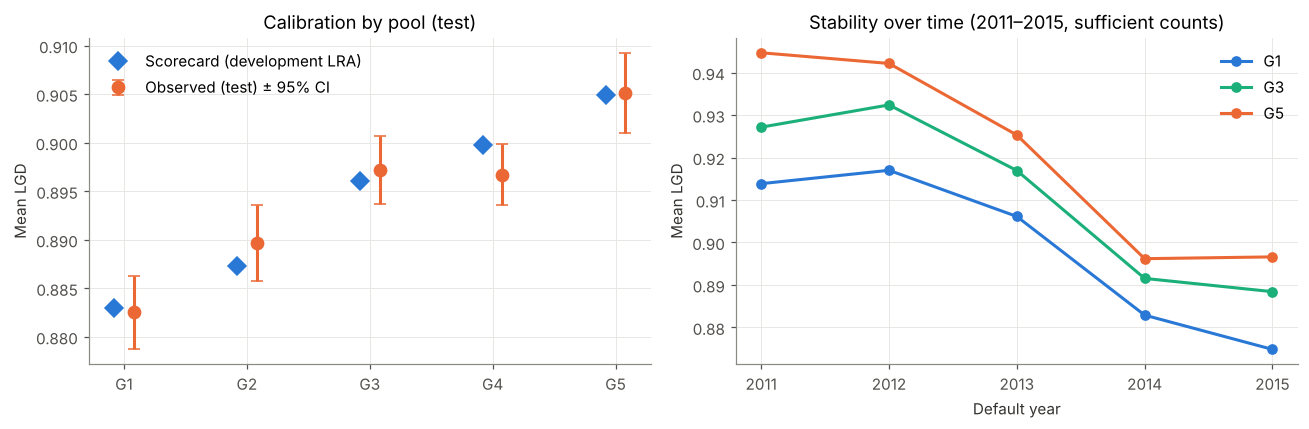

In [12]:
pool_val = (test.groupby("pool", observed=True)
                .agg(n=("lgd", "size"), lgd_observed=("lgd", "mean"), lgd_scorecard=("lgd_sc", "mean"),
                     lgd_beta_regr=("lgd_br", "mean")).sort_index())
# Mean-difference t-test by pool
pool_val["t-stat (obs - scorecard)"] = [
    (g.lgd.mean() - g.lgd_sc.mean()) / (g.lgd.std(ddof=1) / np.sqrt(len(g))) for _, g in test.groupby("pool", observed=True)]
display(pool_val)

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
xs = np.arange(len(pool_val))
se = test.groupby("pool", observed=True).lgd.agg(lambda s: 1.96 * s.std(ddof=1) / np.sqrt(len(s))).reindex(pool_val.index)
ax[0].errorbar(xs + 0.08, pool_val["lgd_observed"], yerr=se, fmt="o", ms=8, color=C2, capsize=4, label="Observed (test) ± 95% CI")
ax[0].plot(xs - 0.08, pool_val["lgd_scorecard"], "D", ms=8, color=C1, label="Scorecard (development LRA)")
ax[0].set(xticks=xs, xticklabels=pool_val.index, title="Calibration by pool (test)", ylabel="Mean LGD")
ax[0].legend(loc="upper left")
stab = test[test.default_year >= 2011].groupby(["default_year", "pool"], observed=True).lgd.mean().unstack()
for col, c in zip(stab.columns[[0, len(stab.columns) // 2, -1]], [C1, C3, C2]):
    ax[1].plot(stab.index, stab[col], marker="o", color=c, label=col)
ax[1].set(title="Stability over time (2011–2015, sufficient counts)", xlabel="Default year", ylabel="Mean LGD")
ax[1].legend(loc="upper right"); ax[1].set_xticks(stab.index.astype(int))
plt.tight_layout(); plt.show()

**Validation results**:
- **Weak discriminatory power for both models** (test CAP Gini: ≈ 8% for the scorecard, ≈ 13% for the logit + Beta regression
  model; RMSE barely below that of the simple mean). This is consistent with recoveries being largely "pooled" through debt sales:
  individual information explains little of the final loss.
- **The scorecard is monotonic and well calibrated out of sample**: LGD rises steadily from G1 (88.3%) to G5 (90.5%) and no
  observed-vs-estimated gap is significant at the 5% level (|t| < 1.96).
- **The parametric model ranks better but raises two red flags**: (i) a calibration bias of about −0.3 points (mean predicted LGD
  0.8905 vs 0.8933 observed), due to the non-linear transformation – it would need recalibration; (ii) **sign reversals** (e.g.
  share of principal repaid: positive coefficient on P(RR=0) although the bivariate relationship is clearly decreasing), caused by
  collinearity with months on book. This kind of economic inconsistency is precisely what an expert-judgement scorecard avoids by
  construction.
- LGD differences across default years (up to 5 points) are **of the same order as the gap between the extreme pools**
  (≈ 2 points): long-run-average calibration and *downturn* analysis weigh more than segmentation.

## 8. Recovery-rate densities by pool: scorecard × Beta kernel vs Beta distribution by pool

The scorecard provides the segmentation; the **Beta kernel** then provides, for each pool, the full recovery-rate distribution
(mass at 0 + continuous density). This yields LGD quantiles by pool, useful for *downturn LGD*, stress testing or economic
capital. It is compared with a Beta distribution (MLE) fitted by pool.

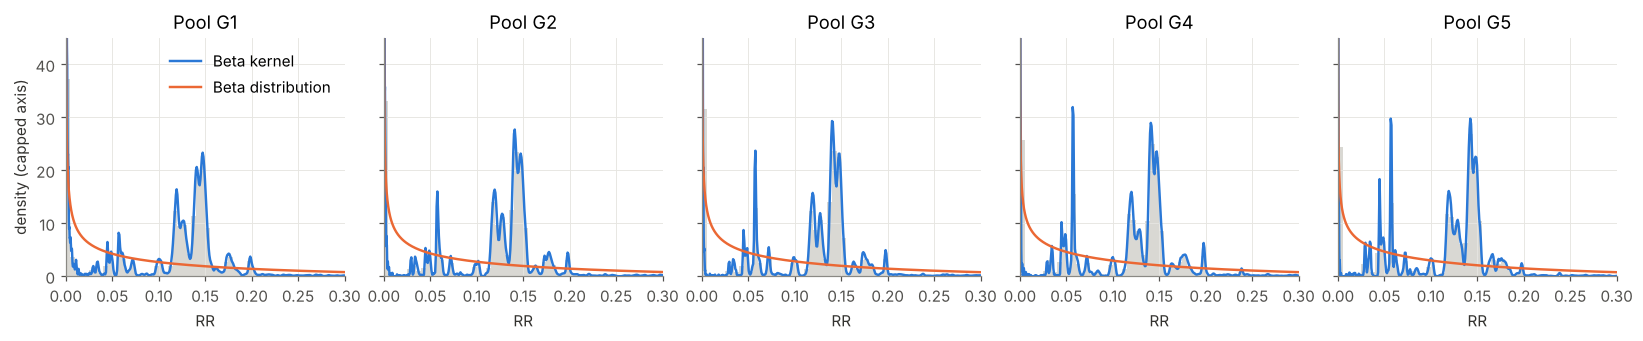

,P(RR=0),test LL – Beta kernel,test LL – Beta distr.,LGD median – kernel,LGD median – Beta,LGD median – empirical test,LGD q75 – kernel,LGD q75 – Beta,LGD q75 – empirical test
pool,,,,,,,,,
G1,0.0694,2.0909,1.1952,0.8758,0.9382,0.8742,0.9919,0.9880,0.9923
G2,0.1144,2.2377,1.2284,0.8750,0.9428,0.8777,0.9972,0.9912,0.9989
G3,0.1575,2.3503,1.2242,0.8798,0.9511,0.8809,0.9994,0.9949,0.9994
G4,0.1886,2.2919,1.1381,0.8812,0.9526,0.8804,0.9997,0.9964,0.9997
G5,0.1979,2.3322,1.2091,0.8824,0.9546,0.8830,0.9998,0.9971,0.9997


In [13]:
pool_dist = []
fig, axes = plt.subplots(1, len(calib), figsize=(15, 3.2), sharey=True)
for ax_, (pool, g_tr) in zip(axes, train.groupby("pool", observed=True)):
    g_te = test[test.pool == pool]
    r_tr, r_te = g_tr.rr.to_numpy(), g_te.rr.to_numpy()
    yp_tr, yp_te = r_tr[(r_tr > 0) & (r_tr < 1)], r_te[(r_te > 0) & (r_te < 1)]
    p0_g, p1_g = (r_tr == 0).mean(), (r_tr == 1).mean()
    a_g, b_g, _, _ = stats.beta.fit(yp_tr, floc=0, fscale=1)
    sample = RNG.choice(yp_tr, min(6000, len(yp_tr)), replace=False)
    f_k = kde_beta(GRID, sample, bw["Beta kernel (Chen)"])
    f_b = stats.beta.pdf(GRID, a_g, b_g)
    F_k, F_b = cdf_from_density(f_k), cdf_from_density(f_b)
    pool_dist.append({
        "pool": pool, "P(RR=0)": p0_g,
        "test LL – Beta kernel": np.log(np.maximum(np.interp(yp_te, GRID, f_k), 1e-12)).mean(),
        "test LL – Beta distr.": np.log(np.maximum(stats.beta.pdf(yp_te, a_g, b_g), 1e-12)).mean(),
        "LGD median – kernel": 1 - mixed_rr_quantile(0.50, F_k, p0_g, p1_g),
        "LGD median – Beta": 1 - mixed_rr_quantile(0.50, F_b, p0_g, p1_g),
        "LGD median – empirical test": 1 - np.quantile(r_te, 0.50),
        "LGD q75 – kernel": 1 - mixed_rr_quantile(0.25, F_k, p0_g, p1_g),
        "LGD q75 – Beta": 1 - mixed_rr_quantile(0.25, F_b, p0_g, p1_g),
        "LGD q75 – empirical test": 1 - np.quantile(r_te, 0.25),
    })
    ax_.hist(yp_tr, bins=120, range=(0, .6), density=True, color="#d9d8d3", edgecolor="none")
    ax_.plot(GRID, f_k, color=C1, lw=1.6, label="Beta kernel"); ax_.plot(GRID, f_b, color=C2, lw=1.6, label="Beta distribution")
    ax_.set(title=f"Pool {pool}", xlim=(0, .3), ylim=(0, 45), xlabel="RR")
axes[0].set_ylabel("density (capped axis)"); axes[0].legend(loc="upper right")
plt.tight_layout(); plt.show()
display(pd.DataFrame(pool_dist).set_index("pool"))

**Reading**: in every pool, the Beta kernel clearly outperforms the Beta distribution in out-of-sample likelihood and matches the
observed median within half a point, whereas the Beta distribution overstates it by 6 to 7 points. Combining "scorecard for
segmentation + Beta kernel for the within-pool distribution" therefore delivers usable LGD distributions by pool (stress testing,
economic capital) while keeping pool means calibrated to the long-run average.

### *Downturn* illustration (simplified)

The EBA guidelines on *downturn LGD* (EBA/GL/2019/03) require institutions to identify downturn periods and quantify the
corresponding LGD. Purely for illustration, the long-run average (LRA) is compared with the mean LGD of the worst default year in
the available history – not to be confused with a regulatory calibration, which requires an analysis of economic indicators
(GDP, unemployment, etc.) and recovery periods.

In [14]:
by_year = df.groupby("default_year").agg(n=("lgd", "size"), lgd=("lgd", "mean"))
by_year_robust = by_year[by_year.n >= 300]
lra = df.lgd.mean()
worst = by_year_robust.lgd.idxmax()
print(f"Long-run average LGD (default-weighted): {lra:.4f}")
print(f"Worst default year (≥ 300 defaults)    : {int(worst)} – LGD {by_year_robust.lgd.max():.4f}")
print(f"Illustrative downturn add-on           : +{by_year_robust.lgd.max() - lra:.4f}")
display(by_year)

Long-run average LGD (default-weighted): 0.8934
Worst default year (≥ 300 defaults)    : 2012 – LGD 0.9368
Illustrative downturn add-on           : +0.0434


,n,lgd
default_year,,
2008,183,0.9448
2009,386,0.9359
2010,676,0.9315
2011,1185,0.9167
2012,2628,0.9368
2013,6457,0.9119
2014,14947,0.8894
2015,31595,0.8854


**Caveat**: the worst year in the sample (2012) does not correspond to an economic downturn: the 2008–2012 default years combine
small counts with loans from the platform's earliest vintages. A compliant *downturn* calibration would require identifying
downturn periods from macroeconomic indicators (RTS on economic downturn) – the Lending Club history, which covers the 2008–2009
crisis poorly, is insufficient for that purpose.

## 9. Limitations and next steps

1. **Discounting**: regulatory workout LGD discounts recovery cash flows back to the default date (reference rate + add-on, see
   EBA/GL/2017/16). Lending Club does not provide recovery cash-flow dates, so LGD here is undiscounted and therefore slightly
   understated.
2. **Costs**: only direct collection fees (`collection_recovery_fee`) are deducted; indirect costs (internal workout management)
   should be allocated.
3. **Incomplete workouts**: handled here by excluding 2016+ defaults; an alternative is to model future recoveries (chain-ladder,
   survival models) to keep these observations.
4. **Representativeness**: US unsecured consumer loans sold to debt buyers – not directly transferable to a European banking
   portfolio (mortgages, SMEs, corporates), where LGD is typically bimodal and strongly driven by collateral.
5. **Next steps**: (i) a separate cure-rate model for portfolios where returns to performing status are frequent; (ii) a Beta kernel
   with multiplicative bias correction (Hirukawa, 2010); (iii) a conditional Beta kernel or quantile regression for LGD quantiles
   by factor; (iv) a validation pack: calibration tests by pool, stability (PSI), annual backtesting.

**References**
- Renault, O. & Scaillet, O. (2004), *On the way to recovery: A nonparametric bias free estimation of recovery rate densities*, Journal of Banking & Finance 28(12).
- Chen, S.X. (1999), *Beta kernel estimators for density functions*, Computational Statistics & Data Analysis 31.
- Ferrari, S. & Cribari-Neto, F. (2004), *Beta regression for modelling rates and proportions*, Journal of Applied Statistics 31.
- Hirukawa, M. (2010), *Nonparametric multiplicative bias correction for kernel-type density estimation on the unit interval*, Computational Statistics & Data Analysis 54(2).
- Smithson, M. & Verkuilen, J. (2006), *A better lemon squeezer? Maximum-likelihood regression with beta-distributed dependent variables*, Psychological Methods 11.
- EBA (2017), *Guidelines on PD estimation, LGD estimation and the treatment of defaulted exposures* (EBA/GL/2017/16); EBA (2019), *Guidelines for the estimation of LGD appropriate for an economic downturn* (EBA/GL/2019/03).